In [1]:
# Install required packages
%pip install openpyxl joblib streamlit wordcloud seaborn scikit-learn


  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.1
    Uninstalling protobuf-7.34.1:
      Successfully uninstalled protobuf-7.34.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [wordcloud]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import string
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

import joblib

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")

# Random seed for reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully.")


All libraries imported successfully.


In [3]:
# Define the dataset file
file_path = Path("P652-Dataset.xlsx")

# Check whether the file exists
if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path.resolve()}\n"
        "Please place 'P652-Dataset.xlsx' in the same folder as this notebook."
    )

# Load the Excel dataset
df = pd.read_excel(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset path:", file_path.resolve())
print("Shape:", df.shape)

# Display the first 5 rows
display(df.head())


Dataset loaded successfully!
Dataset path: /Users/keziabethapudi/P652-Dataset.xlsx
Shape: (1440, 3)


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset Information:")
df.info()


Shape: (1440, 3)

Columns:
['title', 'rating', 'body']

Data Types:


,dtype
title,object
rating,int64
body,object



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [5]:
print("Missing Values:")
display(df.isnull().sum().to_frame("missing_count"))

print("Duplicate Rows:", df.duplicated().sum())


Missing Values:


,missing_count
title,0
rating,0
body,0


Duplicate Rows: 0


In [6]:
print("\nRating Distribution:")

rating_counts = df["rating"].value_counts().sort_index()

display(rating_counts.to_frame("count"))



Rating Distribution:


,count
rating,
1,386
2,126
3,199
4,310
5,419


In [7]:
print("\nTitle Distribution:")

title_counts = df["title"].value_counts()

display(title_counts.to_frame("count"))



Title Distribution:


,count
title,
Value for money,16
Waste of money,6
Good,6
Average,6
Good phone,5
...,...
Awesome performance,1
Ok In This Budget.,1
"Better battery, poor camera..",1


In [8]:
# Create a clean working copy
data = df.copy()

# Remove exact duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

# Handle missing values and ensure text columns are strings
data["title"] = data["title"].fillna("").astype(str)
data["body"] = data["body"].fillna("").astype(str)

# Remove records with no review body
data = data[data["body"].str.strip().ne("")].reset_index(drop=True)


# Convert ratings into sentiment classes
def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"


data["sentiment"] = data["rating"].apply(rating_to_sentiment)

print("Cleaned dataset shape:", data.shape)

print("\nSentiment Distribution:")
display(data["sentiment"].value_counts().to_frame("count"))

print("\nFirst 5 rows of cleaned data:")
display(data.head())


Cleaned dataset shape: (1440, 4)

Sentiment Distribution:


,count
sentiment,
Positive,729
Negative,512
Neutral,199



First 5 rows of cleaned data:


,title,rating,body,sentiment
0,Horrible product,1,Very disappointed with the overall performance...,Negative
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Neutral
2,Overall,4,"Got the mobile on the launch date,Battery must...",Positive
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,Negative
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Negative


In [9]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Apply text cleaning
data["clean_text"] = data["body"].apply(clean_text)

# Display original and cleaned text
display(
    data[["body", "clean_text", "sentiment"]].head()
)


,body,clean_text,sentiment
0,Very disappointed with the overall performance...,very disappointed with the overall performance...,Negative
1,Camera quality is low,camera quality is low,Neutral
2,"Got the mobile on the launch date,Battery must...",got the mobile on the launch datebattery must ...,Positive
3,1. It doesn't work with 5.0GHz WiFi frequency....,it doesnt work with ghz wifi frequency ghz is ...,Negative
4,"Not worth buying....faulty software, poor disp...",not worth buyingfaulty software poor display q...,Negative


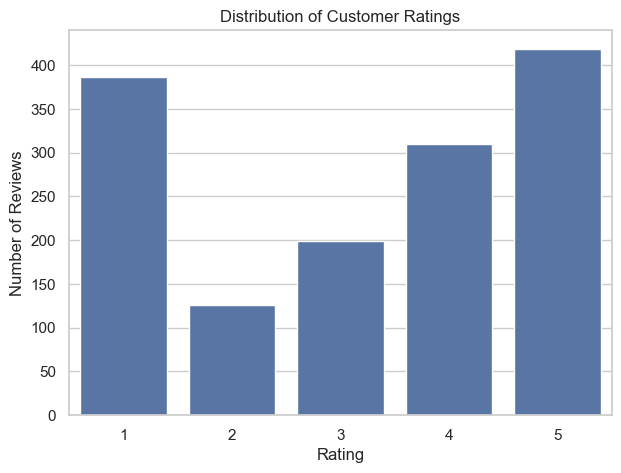

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()


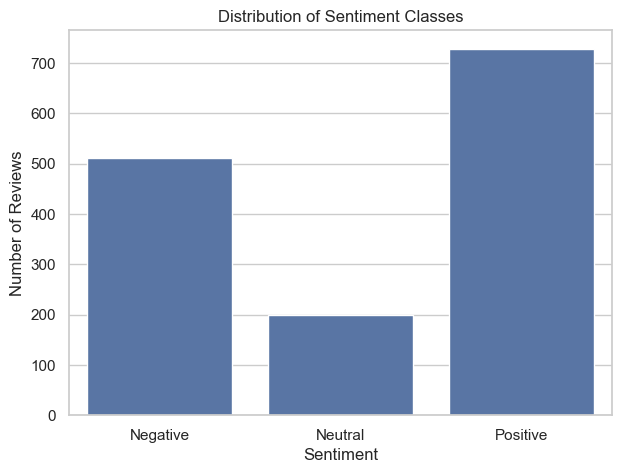

,count
sentiment,
Negative,512
Neutral,199
Positive,729


In [11]:
plt.figure(figsize=(7, 5))

order = ["Negative", "Neutral", "Positive"]

sns.countplot(
    data=data,
    x="sentiment",
    order=order
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

# Display the exact counts
display(
    data["sentiment"]
    .value_counts()
    .reindex(order)
    .to_frame("count")
)


In [12]:
# Review length analysis
data["review_length"] = data["body"].str.len()
data["word_count"] = data["body"].str.split().str.len()

# Display descriptive statistics
display(
    data[["review_length", "word_count", "rating"]].describe()
)


,review_length,word_count,rating
count,1440.000000,1440.000000,1440.000000
mean,302.109028,52.892361,3.173611
std,225.733052,39.346259,1.584453
min,4.000000,1.000000,1.000000
25%,170.000000,29.000000,1.000000
50%,246.000000,43.000000,4.000000
75%,359.000000,63.250000,5.000000
max,2490.000000,385.000000,5.000000


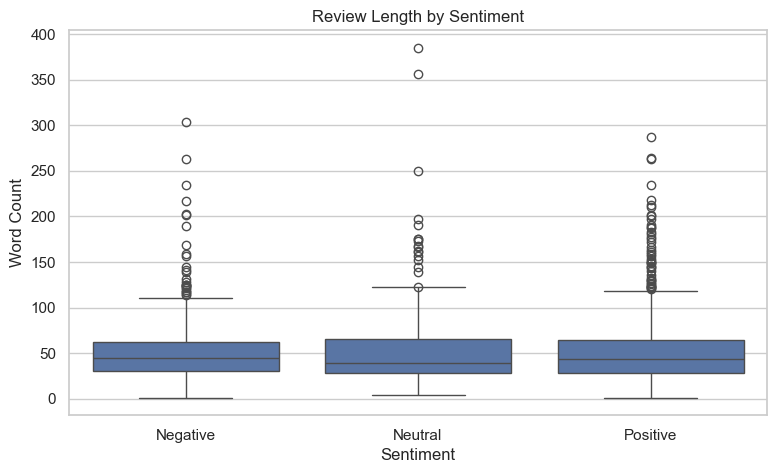

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="sentiment",
    y="word_count",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")

plt.show()


In [14]:
# Average rating and review length by sentiment
sentiment_summary = (
    data.groupby("sentiment")
    .agg(
        reviews=("sentiment", "size"),
        average_rating=("rating", "mean"),
        average_words=("word_count", "mean"),
    )
    .reindex(["Negative", "Neutral", "Positive"])
)

display(sentiment_summary)


,reviews,average_rating,average_words
sentiment,,,
Negative,512,1.246094,52.119141
Neutral,199,3.000000,56.527638
Positive,729,4.574760,52.443073


In [15]:
# Skewness and Kurtosis
review_length_skewness = data["review_length"].skew()
review_length_kurtosis = data["review_length"].kurt()

print("Skewness of Review Length:", review_length_skewness)
print("Kurtosis of Review Length:", review_length_kurtosis)


Skewness of Review Length: 3.0266081278550403
Kurtosis of Review Length: 15.19343428472099


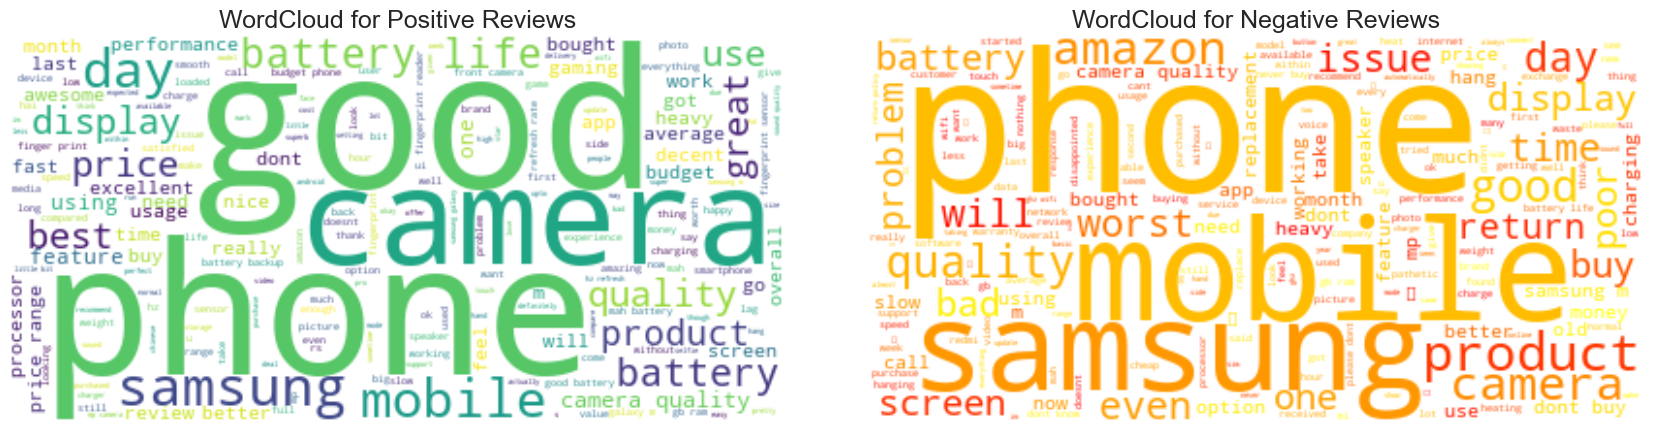

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Combine cleaned text for each sentiment
positive_text = " ".join(
    data[data["sentiment"] == "Positive"]["clean_text"]
)

negative_text = " ".join(
    data[data["sentiment"] == "Negative"]["clean_text"]
)

# Generate Positive WordCloud
positive_wc = WordCloud(
    background_color="white",
    max_words=200,
    max_font_size=100,
    random_state=RANDOM_STATE
).generate(positive_text)

# Generate Negative WordCloud
negative_wc = WordCloud(
    background_color="white",
    max_words=200,
    max_font_size=100,
    random_state=RANDOM_STATE,
    colormap="autumn"
).generate(negative_text)

# Display Positive WordCloud
axes[0].imshow(positive_wc, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title(
    "WordCloud for Positive Reviews",
    fontsize=18
)

# Display Negative WordCloud
axes[1].imshow(negative_wc, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title(
    "WordCloud for Negative Reviews",
    fontsize=18
)

plt.tight_layout(pad=5)
plt.show()


In [17]:
# Define features and target
X = data["clean_text"]
y = data["sentiment"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining Class Distribution:")

display(
    y_train.value_counts(normalize=True)
    .rename("proportion")
    .to_frame()
)


Training samples: 1152
Testing samples : 288

Training Class Distribution:


,proportion
sentiment,
Positive,0.506076
Negative,0.355903
Neutral,0.138021


In [18]:
# Create machine-learning pipelines
models = {
    "Logistic Regression": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                max_features=20000
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]),

    "Multinomial Naive Bayes": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                max_features=20000
            )
        ),
        (
            "model",
            MultinomialNB()
        )
    ]),

    "Linear SVM": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                max_features=20000
            )
        ),
        (
            "model",
            LinearSVC(
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ])
}

print("Models created successfully:")
for model_name in models:
    print("-", model_name)


Models created successfully:
- Logistic Regression
- Multinomial Naive Bayes
- Linear SVM


In [19]:
# Train and evaluate the models

results = []
trained_models = {}

for name, pipeline in models.items():
    print(f"Training {name}...")

    # Train the model
    pipeline.fit(X_train, y_train)

    # Make predictions on test data
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision (Macro)": precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    })

    # Store the trained model
    trained_models[name] = pipeline

    print(f"{name} completed.\n")


# Create results DataFrame
results_df = pd.DataFrame(results)

# Sort models by F1-score
results_df = (
    results_df
    .sort_values(
        "F1-Score (Macro)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Model Performance Comparison:")
display(results_df)


Training Logistic Regression...
Logistic Regression completed.

Training Multinomial Naive Bayes...
Multinomial Naive Bayes completed.

Training Linear SVM...
Linear SVM completed.

Model Performance Comparison:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Logistic Regression,0.743056,0.616750,0.620700,0.617320
1,Linear SVM,0.750000,0.592797,0.599096,0.587170
2,Multinomial Naive Bayes,0.704861,0.495678,0.522562,0.492653


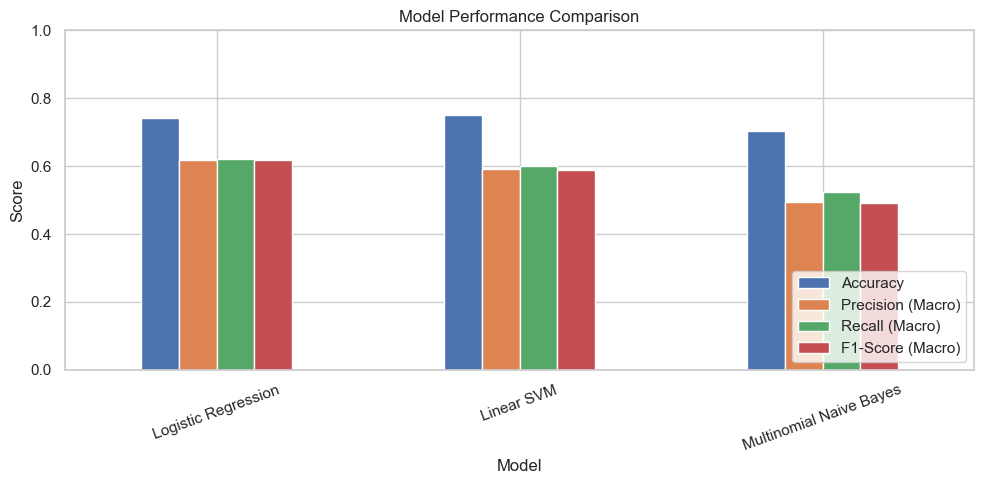

In [20]:
# Select performance metrics for plotting
plot_df = results_df.set_index("Model")[
    [
        "Accuracy",
        "Precision (Macro)",
        "Recall (Macro)",
        "F1-Score (Macro)"
    ]
]

# Create comparison chart
ax = plot_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


In [21]:
# Select the best model based on Macro F1-Score
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

# Generate predictions using the best model
best_predictions = best_model.predict(X_test)

print("Selected Model:", best_model_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)


Selected Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.83      0.80       102
     Neutral       0.25      0.20      0.22        40
    Positive       0.83      0.83      0.83       146

    accuracy                           0.74       288
   macro avg       0.62      0.62      0.62       288
weighted avg       0.73      0.74      0.74       288



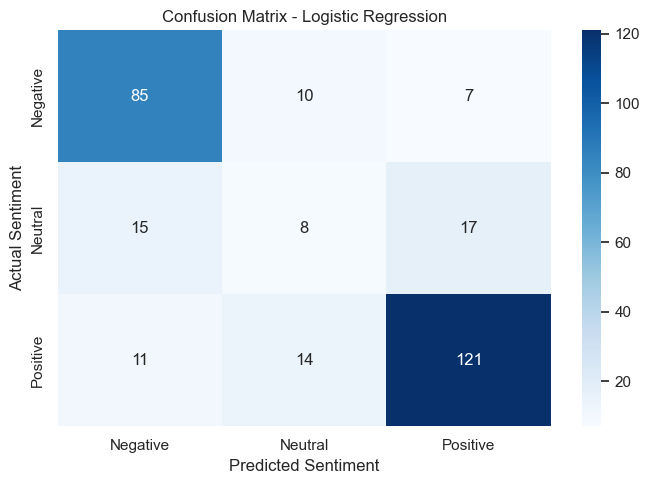

In [22]:
# Create confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Negative", "Neutral", "Positive"]
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()


In [23]:
# Get the final model and TF-IDF vectorizer
final_estimator = best_model.named_steps["model"]
vectorizer = best_model.named_steps["tfidf"]

# Check whether the model has coefficients
if hasattr(final_estimator, "coef_"):
    
    # Get feature names from TF-IDF
    feature_names = np.array(
        vectorizer.get_feature_names_out()
    )
    
    coefficients = final_estimator.coef_
    classes = final_estimator.classes_

    print("Model:", best_model_name)
    print("Number of features:", len(feature_names))
    print()

    # Display top features for each sentiment class
    if len(classes) == 2:
        
        for idx, class_name in enumerate(classes):
            top_idx = np.argsort(
                coefficients[idx]
            )[-15:][::-1]

            print(f"Top terms for {class_name}:")
            print(", ".join(feature_names[top_idx]))
            print()

    else:
        
        for idx, class_name in enumerate(classes):
            top_idx = np.argsort(
                coefficients[idx]
            )[-15:][::-1]

            print(
                f"Top terms associated with {class_name}:"
            )
            print(", ".join(feature_names[top_idx]))
            print()

else:
    print(
        "The selected model does not expose linear coefficients."
    )


Model: Logistic Regression
Number of features: 7832

Top terms associated with Negative:
worst, amazon, return, dont, issue, buy, even, not working, disappointed, poor, product, they, samsung, bad, we

Top terms associated with Neutral:
average, not, expected, other, over, but, slow, not that, look, camera quality, will, brightness, mark, quality, cam

Top terms associated with Positive:
best, good, battery, awesome, excellent, nice, great, very good, price, for, budget, fingerprint, it, value for, bit



In [24]:
def predict_sentiment(review_text):
    # Clean the new review
    cleaned = clean_text(review_text)

    # Predict sentiment
    prediction = best_model.predict([cleaned])[0]

    # Store result
    result = {
        "Review": review_text,
        "Predicted Sentiment": prediction
    }

    # Add decision score if supported by the model
    final_model = best_model.named_steps["model"]

    if hasattr(final_model, "decision_function"):
        scores = best_model.decision_function([cleaned])
        result["Decision Score"] = scores.tolist()[0]

    return result


# Test the prediction function
examples = [
    "The product quality is excellent and I am very happy with my purchase.",
    "The product is okay, but the camera quality is average.",
    "Very disappointed. The product stopped working and is not worth the money."
]

for review in examples:
    display(
        pd.DataFrame(
            [predict_sentiment(review)]
        )
    )


,Review,Predicted Sentiment,Decision Score
0,The product quality is excellent and I am very...,Positive,"[-0.06847873892103581, -0.5572166109144492, 0...."


,Review,Predicted Sentiment,Decision Score
0,"The product is okay, but the camera quality is...",Neutral,"[-0.5060245978487453, 0.6589417092912154, -0.1..."


,Review,Predicted Sentiment,Decision Score
0,Very disappointed. The product stopped working...,Negative,"[1.0375647625625302, -0.6023961103552803, -0.4..."


In [25]:
# Create model directory
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

# Define model file path
model_path = MODEL_DIR / "sentiment_model.joblib"

# Save the trained model
joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved model:", model_path.resolve())
print("Best model:", best_model_name)


Model saved successfully!
Saved model: /Users/keziabethapudi/model/sentiment_model.joblib
Best model: Logistic Regression
